# PAYGo portfolio analysis: should the investor invest?

Case Study 5, 04-782 Energy Data Analytics

**Question:** a Nigerian PAYGo solar company asks for investment. Is its loan book good enough, and on what terms
should the investment committee say yes or no?

**Data:** 25,685 contracts sold October 2023 to July 2026 and 275,172 monthly payment records (₦), financial records
to 31 July 2026, status snapshot on 10 August 2026.

**Approach:** I start from the TA's starter notebook (same cleaning, same payment-allocation assumption, same checks),
then measure the whole portfolio with the five GOGLA PAYGo PERFORM KPIs, follow every sales cohort over its contract
term, look for what drives the differences, size the risk in today's book and project what the open contracts will
eventually repay.

**Answer (details in Section 13): not the full investment now; a smaller first tranche with conditions.**

- The contracts that have run their full course are excellent: **93–94% repaid and 85% owned at twice the term**,
  above GOGLA's peer averages (72–77% and 78%). But they are mostly 2023–early 2024 sales.
- The book the money would fund is clearly weaker. The same product at the same stage of its term now repays about
  **20 points less** (Z17 at 90% of term: 80% for Q4 2023 sales, 60–61% for Q2–Q3 2025 sales). Mid-term customers pay
  about **58%** of each month's dues, against about 75% in 2024. **Half of active customers are locked out.**
- Since late 2025 about half of new lending has gone to **large Tier 4–5 systems**, some with no deposit at all, and
  these start worse.
- I project the 2025 cohorts will end at about **78–80% repaid**. That is around the peer average, not above it, and
  there are no cost data to show it is profitable.

So I would fund only proven products with a real deposit, and release more money only if cohort repayment stops
falling.

## 0. Setup and assumptions

Every setting is in the next two cells. The two CSVs sit in `data/` next to this notebook (the TA's layout).
Figures go to `outputs/figures` and tables to `outputs/tables`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, FuncFormatter, MultipleLocator
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
DATA_FOLDER = Path("data")
FIG_DIR = Path("outputs/figures")
TAB_DIR = Path("outputs/tables")
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FINANCIAL_DATE = pd.Timestamp("2026-07-31")   # receipts and due amounts end here
STATUS_DATE = pd.Timestamp("2026-08-10")      # contract_status, payment_due_date, days_locked
EXAMPLE_ID = 17112                            # the lecture's worked contract
MIN_COHORT_SIZE = 100                         # GOGLA: at least 100 contracts per cohort and data point
RECENT_WINDOW_START = pd.Timestamp("2025-08-01")  # "last 12 months" for the recent-behaviour checks

# GOGLA benchmarks quoted in the lecture (historical context, not hurdles)
BENCH_PVP_2X = {"Overall sample": 0.72, "West Africa": 0.77, "East Africa": 0.69}
BENCH_OR_2X = 0.78
GOGLA_ILLUSTRATIVE_TARGET = 0.80

# plot style (validated palette: categorical slots in fixed order, one ordinal blue ramp for ordered cohorts)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RAMP5 = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # oldest -> newest cohort
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "lines.linewidth": 1.8,
})
pct = PercentFormatter(1, decimals=0)
naira_m = FuncFormatter(lambda v, _: f"₦{v:,.0f}M")


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    return df

## 1. Data and cleaning checks

### 1.1 Load the files (as in the TA notebook)

In [3]:
contracts = pd.read_csv(DATA_FOLDER / "261113_contracts_vfinal.csv")
payments = pd.read_csv(DATA_FOLDER / "261113_payments_vfinal.csv")
for column in ["purchase_date", "paid_off_date", "payment_due_date"]:
    contracts[column] = pd.to_datetime(contracts[column], format="%m/%d/%y")
payments["payment_month"] = pd.to_datetime(payments["payment_month"])
print(f"{len(contracts):,} contracts; {len(payments):,} monthly payment records")
print(f"Sales from {contracts.purchase_date.min():%d %b %Y} to {contracts.purchase_date.max():%d %b %Y}; "
      f"payments from {payments.payment_month.min():%b %Y} to {payments.payment_month.max():%b %Y}")

25,685 contracts; 275,172 monthly payment records
Sales from 01 Oct 2023 to 31 Jul 2026; payments from Oct 2023 to Jul 2026


### 1.2 The TA's checks, reproduced

Keys, joins, signs and dates; the two payment totals; the payoff-date conflict; missing segments; and milestone
eligibility. The `assert`s stop the notebook if any of these differ from the TA's results.

In [4]:
assert contracts["contract_id"].is_unique
assert not payments.duplicated(["contract_id", "payment_month"]).any()
assert payments["contract_id"].isin(contracts["contract_id"]).all()
assert (payments["amount_paid"] > 0).all()
assert (payments["payment_month"] <= FINANCIAL_DATE).all() and payments["payment_month"].dt.is_month_start.all()

ledger_total = payments.groupby("contract_id")["amount_paid"].sum()
portfolio = contracts.copy()
portfolio["ledger_total"] = portfolio["contract_id"].map(ledger_total).fillna(0)
portfolio["payment_difference"] = portfolio["ledger_total"] - portfolio["total_paid"]
portfolio["reconciles"] = np.isclose(portfolio["payment_difference"], 0)
assert (~portfolio["reconciles"]).sum() == 341

payoff_conflict = (portfolio["contract_status"] == "PAID_OFF") != portfolio["paid_off_date"].notna()
assert portfolio.loc[payoff_conflict, "contract_id"].tolist() == [13843]

missing = portfolio[["seller_type", "product_tier", "region"]].isna().sum()
assert missing.tolist() == [1476, 6429, 7914]
portfolio["seller"] = portfolio["seller_type"].fillna("Unknown")
portfolio["tier"] = portfolio["product_tier"].fillna("Unknown")
portfolio["region_f"] = portfolio["region"].fillna("Unknown")

portfolio["term_days"] = portfolio["deposit_days"] + portfolio["financed_days"]
portfolio["day90_date"] = portfolio["purchase_date"] + pd.Timedelta(days=90)
portfolio["twice_term_date"] = portfolio["purchase_date"] + pd.to_timedelta(2 * portfolio["term_days"], unit="D")
assert (portfolio["day90_date"] <= FINANCIAL_DATE).equals(portfolio["due_at_90d"].notna())
assert (portfolio["twice_term_date"] <= FINANCIAL_DATE).equals(portfolio["due_at_2x"].notna())
print("Conflicting payment totals:", (~portfolio["reconciles"]).sum())
print("Reached day 90:", portfolio["due_at_90d"].notna().sum(), "| reached twice-term:", portfolio["due_at_2x"].notna().sum())
print("Missing:", missing.to_dict())

Conflicting payment totals: 341
Reached day 90: 23765 | reached twice-term: 4825
Missing: {'seller_type': 1476, 'product_tier': 6429, 'region': 7914}


### 1.3 Extra checks I added

The TA notebook covers the main issues. Looking more closely at the files turned up six more things to note and
one useful finding (the last row):

In [5]:
first_month = portfolio["purchase_date"].dt.to_period("M").dt.to_timestamp()
first_receipt = payments.merge(portfolio[["contract_id"]].assign(m=first_month), on="contract_id")
first_receipt = first_receipt.loc[first_receipt["payment_month"] == first_receipt["m"]].set_index("contract_id")["amount_paid"]
portfolio["first_month_cash"] = portfolio["contract_id"].map(first_receipt).fillna(0)
paid_off = portfolio["contract_status"] == "PAID_OFF"

extra_checks = pd.DataFrame([
    ("Contracts with no payment rows at all", (portfolio["ledger_total"] == 0).sum(),
     "Kept; zero cash. They count against repayment."),
    ("Zero-deposit contracts", (portfolio["deposit"] == 0).sum(),
     "Kept. All are models Z28 (242) and Z34 (116); they perform poorly (Section 9)."),
    ("Cash in the sale month below the deposit", (portfolio["first_month_cash"] < portfolio["deposit"]).sum(),
     "Kept. Subtracting the full deposit (TA rule) makes these slightly conservative."),
    ("Ledger total above the full contract price", (portfolio["ledger_total"] > portfolio["cash_price"]).sum(),
     "Overpayment. The cap at amount due removes it from every KPI."),
    ("Not PAID_OFF but ledger >= contract price", ((~paid_off) & (portfolio["ledger_total"] >= portfolio["cash_price"])).sum(),
     "All among the 341 conflicts; the ledger looks overstated here."),
    ("PAID_OFF with snapshot total below price", (paid_off & (portfolio["total_paid"] < portfolio["cash_price"])).sum(),
     "None, so the payoff date is consistent with receipts."),
    ("Original schedule rebuilt exactly (see 2.1)", len(portfolio),
     "due_to_date and due_at_90d reproduced for every contract."),
], columns=["Check", "Contracts", "Treatment"]).set_index("Check")
display(save_table(extra_checks, "data_checks_extra"))

conflicts = portfolio.loc[~portfolio["reconciles"]]
print(f"The 341 conflicts: ledger above snapshot in {(conflicts.payment_difference > 0).sum()}, "
      f"net ₦{conflicts.payment_difference.sum()/1e6:,.1f}M = "
      f"{conflicts.payment_difference.sum()/portfolio.ledger_total.sum():.2%} of all receipts")

,Contracts,Treatment
Check,,
Contracts with no payment rows at all,8,Kept; zero cash. They count against repayment.
Zero-deposit contracts,358,Kept. All are models Z28 (242) and Z34 (116); ...
Cash in the sale month below the deposit,1056,Kept. Subtracting the full deposit (TA rule) m...
Ledger total above the full contract price,1974,Overpayment. The cap at amount due removes it ...
Not PAID_OFF but ledger >= contract price,9,All among the 341 conflicts; the ledger looks ...
PAID_OFF with snapshot total below price,0,"None, so the payoff date is consistent with re..."
Original schedule rebuilt exactly (see 2.1),25685,due_to_date and due_at_90d reproduced for ever...


The 341 conflicts: ledger above snapshot in 339, net ₦4.0M = 0.12% of all receipts


Missing segments are not random: they come almost entirely from the early sales cohorts. Region is missing for 90%
of contracts sold in Q4 2023 and for 5% or less of contracts sold since Q4 2025. Any comparison by region or tier is therefore
partly a comparison of old and new contracts. I keep "Unknown" as its own group and compare segments within the same
sales month and product (Section 9).

In [6]:
portfolio["cohort"] = portfolio["purchase_date"].dt.to_period("M")
portfolio["cohort_q"] = portfolio["purchase_date"].dt.to_period("Q")
missing_by_q = portfolio.groupby("cohort_q")[["seller_type", "product_tier", "region"]].apply(lambda g: g.isna().mean())
display(save_table(missing_by_q.T.round(2), "missing_by_quarter"))

cohort_q,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
seller_type,0.270,0.160,0.150,0.100,0.060,0.040,0.020,0.000,0.000,0.000,0.000,0.000
product_tier,0.340,0.810,0.830,0.650,0.350,0.220,0.090,0.030,0.000,0.000,0.000,0.000
region,0.900,0.800,0.750,0.520,0.410,0.250,0.160,0.090,0.030,0.040,0.050,0.020


**Cleaning decisions** (GOGLA asks for exclusions and edge cases to be disclosed, Technical Guide p. 22):

| Issue | Decision |
|---|---|
| Two sources of cumulative cash | Use the monthly ledger, as the TA does. Switching to the snapshot `total_paid` changes portfolio PvP by 0.05 points (checked in Section 4). The conflicts add up to ₦4.0M, 0.12% of all receipts. |
| 341 conflicts, payoff conflict on 13843 | Keep and flag; no contract is excluded. |
| Missing channel / tier / region | Keep as "Unknown". |
| Payments applied vs cash received | Use the TA's stated assumption: applied = min(max(cumulative cash − deposit, 0), instalments due). It is a conditional estimate, not a GOGLA-standard figure, because the files have no daily allocation ledger. |
| Payment timing inside a month | Lower and upper bounds as in the TA notebook, plus a pro-rata midpoint (cutoff-month cash spread evenly over the month) for single-number summaries. |
| Exclusions | None. All 25,685 contracts, all statuses, including repossessed and written-off ones. |

## 2. Measurement tools

### 2.1 Rebuilding the original schedule

The `due_*` fields only give the schedule at three dates. To measure a cohort at any point in its term (GOGLA's
standard time axis is *% of contract term elapsed*) I need the schedule at any date. The supplied fields are
reproduced exactly by this rule: after the deposit days, one instalment falls due **at the start** of each period
(7 days for weekly plans, 1 day for the 491 daily plans), capped at the amount financed.

In [7]:
n_instalments = np.ceil(portfolio["amount_financed"] / portfolio["instalment"] - 1e-9)
portfolio["period_days"] = np.where((portfolio["financed_days"] / n_instalments).round() == 1, 1, 7)


def due_at(frame, days):
    """Original-schedule instalments due `days` after purchase (excludes deposit)."""
    days = np.asarray(days, dtype=float) * np.ones(len(frame))
    n_due = np.floor((days - frame["deposit_days"].to_numpy()) / frame["period_days"].to_numpy()) + 1
    n_due = np.where(days < frame["deposit_days"].to_numpy(), 0, n_due)
    return np.minimum(np.clip(n_due, 0, None) * frame["instalment"].to_numpy(), frame["amount_financed"].to_numpy())


age_at_report = (FINANCIAL_DATE - portfolio["purchase_date"]).dt.days
assert np.allclose(due_at(portfolio, age_at_report), portfolio["due_to_date"])
has90 = portfolio["due_at_90d"].notna()
assert np.allclose(due_at(portfolio, 90)[has90], portfolio.loc[has90, "due_at_90d"])
print("Rebuilt schedule matches due_to_date and due_at_90d for all", len(portfolio), "contracts")
print("Payment plans:", portfolio["period_days"].map({7: "weekly", 1: "daily"}).value_counts().to_dict())

Rebuilt schedule matches due_to_date and due_at_90d for all 25685 contracts
Payment plans: {'weekly': 25194, 'daily': 491}


### 2.2 Cumulative cash by contract and month, and the measurement function

`cum_cash` holds each contract's cumulative receipts at the end of every month. `measure_at(days)` measures every
contract at its own cutoff (for example day 90, or 2 × term). It returns the lower/upper timing bounds (as in the TA
notebook), the pro-rata midpoint, and whether the contract was fully paid by the cutoff. Contracts that have not reached
the cutoff stay missing, never zero.

In [8]:
MONTHS = pd.period_range(portfolio["cohort"].min(), FINANCIAL_DATE.to_period("M"), freq="M")
monthly_cash = (payments.assign(month=payments["payment_month"].dt.to_period("M"))
                .pivot_table(index="contract_id", columns="month", values="amount_paid", aggfunc="sum")
                .reindex(index=portfolio["contract_id"], columns=MONTHS).fillna(0))
cum_cash = monthly_cash.cumsum(axis=1).to_numpy()
month_index = {m: i for i, m in enumerate(MONTHS)}
deposit = portfolio["deposit"].to_numpy(dtype=float)
financed = portfolio["amount_financed"].to_numpy(dtype=float)
rows_all = np.arange(len(portfolio))


def applied(cash, due):
    """The TA's case assumption: receipts after the deposit, capped at instalments due."""
    return np.minimum(np.clip(cash - deposit, 0, None), due)


def measure_at(days):
    days = np.asarray(days, dtype=float) * np.ones(len(portfolio))
    cutoff = portfolio["purchase_date"] + pd.to_timedelta(days, unit="D")
    eligible = (cutoff <= FINANCIAL_DATE).to_numpy()
    col = np.array([month_index.get(m, len(MONTHS) - 1) for m in cutoff.dt.to_period("M")])
    cash_before = np.where(col > 0, cum_cash[rows_all, np.clip(col - 1, 0, None)], 0.0)
    cash_through = cum_cash[rows_all, col]
    share_of_month = (cutoff.dt.day / cutoff.dt.days_in_month).to_numpy()
    cash_mid = cash_before + (cash_through - cash_before) * share_of_month
    due = due_at(portfolio, days)
    out = pd.DataFrame({"contract_id": portfolio["contract_id"].to_numpy(), "eligible": eligible, "due": due,
                        "cutoff": cutoff.to_numpy()})
    for name, cash in [("lower", cash_before), ("mid", cash_mid), ("upper", cash_through)]:
        out[f"applied_{name}"] = np.where(eligible, applied(cash, due), np.nan)
    out["owned"] = np.where(eligible, (portfolio["paid_off_date"] <= cutoff).to_numpy(), np.nan)
    return out


def summarize(measured, by, frame=None):
    """Add amounts (and counts) within groups before dividing, as GOGLA requires."""
    frame = portfolio if frame is None else frame
    rows = measured.loc[measured["eligible"]].merge(frame, on="contract_id", suffixes=("", "_c"))
    g = rows.groupby(by, observed=True)
    out = g[["due", "applied_lower", "applied_mid", "applied_upper"]].sum()
    out.insert(0, "contracts", g.size())
    for name in ["lower", "mid", "upper"]:
        out[f"pvp_{name}"] = out[f"applied_{name}"] / out["due"]
    out["ownership"] = g["owned"].mean()
    return out

### 2.3 Check against the TA's worked results

Before going further I check that these functions give exactly the TA's numbers.

In [9]:
m90 = measure_at(90)
m2x = measure_at(2 * portfolio["term_days"].to_numpy())
c2 = m90.set_index("contract_id").loc[2]
assert np.isclose(c2.applied_lower / c2.due, 15591 / 21538) and np.isclose(c2.applied_upper / c2.due, 17999 / 21538)
now_applied = applied(portfolio["ledger_total"].to_numpy(), portfolio["due_to_date"].to_numpy())
ex = portfolio["contract_id"] == EXAMPLE_ID
assert np.isclose(now_applied[ex][0], 62872) and np.isclose(now_applied[ex][0] / 109648, 0.5734, atol=5e-5)
assert m2x["eligible"].sum() == 4825

z17_early = portfolio["model_code"].eq("Z17") & portfolio["cohort"].astype(str).between("2023-10", "2023-12")
ta_2x = summarize(m2x, "cohort", portfolio.loc[z17_early])
assert np.allclose(ta_2x["pvp_lower"].round(4), [0.9740, 0.9648, 0.9595])
assert np.allclose(ta_2x["pvp_upper"].round(4), [0.9742, 0.9665, 0.9613])
assert ta_2x["contracts"].tolist() == [384, 449, 380]
assert np.allclose((ta_2x["ownership"] * ta_2x["contracts"]).round().tolist(), [346, 397, 334])
display(ta_2x[["contracts", "pvp_lower", "pvp_upper", "ownership"]])
print("All TA worked results reproduced: contract 17112 57.3%, contract 2 72.4-83.6%, "
      "Z17 twice-term 97.40-97.42% etc., ownership 346/384, 397/449, 334/380")

,contracts,pvp_lower,pvp_upper,ownership
cohort,,,,
2023-10,384,0.974,0.974,0.901
2023-11,449,0.965,0.966,0.884
2023-12,380,0.960,0.961,0.879


All TA worked results reproduced: contract 17112 57.3%, contract 2 72.4-83.6%, Z17 twice-term 97.40-97.42% etc., ownership 346/384, 397/449, 334/380


## 3. What kind of company is this?

Before any KPI: how much the company sells, what it sells, and how that has changed. A portfolio KPI is an average
over this mix, so a change in mix can move the KPI even when customers behave the same.

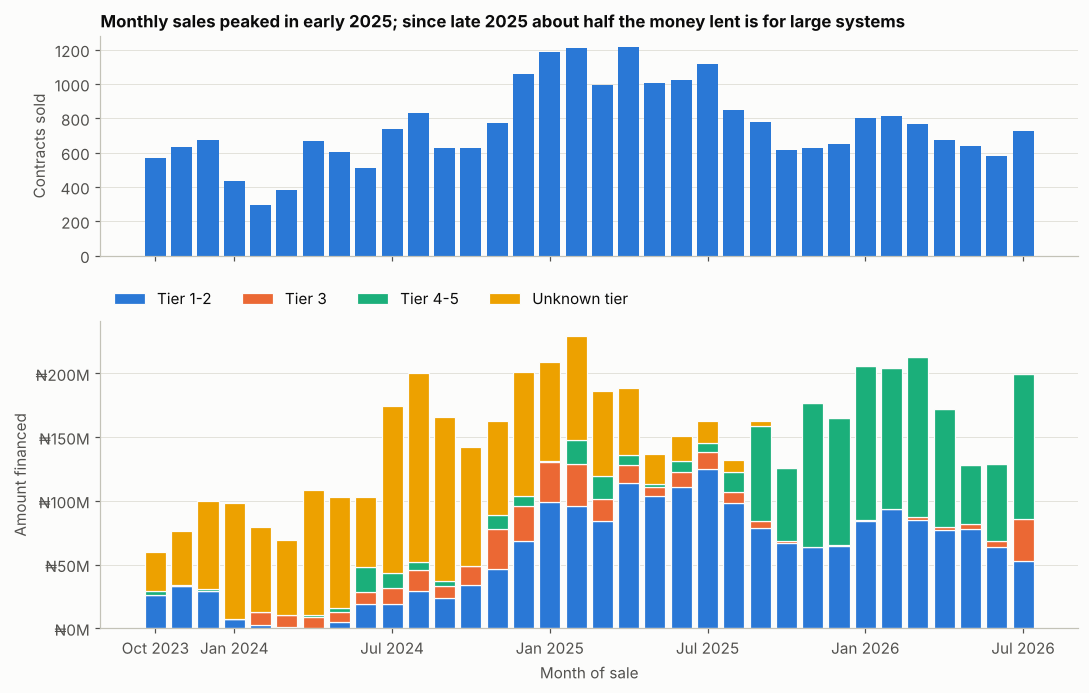

In [10]:
portfolio["tier_group"] = np.select(
    [portfolio["tier"].isin(["Tier 1", "Tier 2"]), portfolio["tier"].eq("Tier 3"),
     portfolio["tier"].isin(["Tier 4", "Tier 5"])],
    ["Tier 1-2", "Tier 3", "Tier 4-5"], default="Unknown tier")
portfolio["deposit_share"] = portfolio["deposit"] / portfolio["cash_price"]

sales = (portfolio.pivot_table(index="cohort", columns="tier_group", values="amount_financed", aggfunc="sum")
         .reindex(columns=["Tier 1-2", "Tier 3", "Tier 4-5", "Unknown tier"]).fillna(0) / 1e6)
counts = portfolio.groupby("cohort").size()

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
x = np.arange(len(sales))
axes[0].bar(x, counts.to_numpy(), width=0.8, color=BLUE)
axes[0].set_ylabel("Contracts sold")
axes[0].set_title("Monthly sales peaked in early 2025; since late 2025 about half the money lent is for large systems")
bottom = np.zeros(len(sales))
for colour, group in zip([BLUE, ORANGE, AQUA, YELLOW], sales.columns):
    axes[1].bar(x, sales[group], bottom=bottom, width=0.8, color=colour, label=group, edgecolor=SURFACE, linewidth=0.8)
    bottom += sales[group].to_numpy()
axes[1].yaxis.set_major_formatter(naira_m)
axes[1].set_ylabel("Amount financed")
axes[1].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ticks = [i for i, p in enumerate(sales.index) if p.month in (1, 7) or i == 0]
axes[1].set_xticks(ticks, [sales.index[i].strftime("%b %Y") for i in ticks])
axes[1].set_xlabel("Month of sale")
fig.tight_layout()
savefig(fig, "fig1_sales_and_mix")
plt.show()

In [11]:
mix = portfolio.groupby("cohort_q").apply(lambda g: pd.Series({
    "contracts": len(g),
    "financed ₦M": g["amount_financed"].sum() / 1e6,
    "avg financed ₦k": g["amount_financed"].mean() / 1e3,
    "Tier 4-5 share of ₦": g.loc[g["tier_group"] == "Tier 4-5", "amount_financed"].sum() / g["amount_financed"].sum(),
    "zero-deposit share of ₦": g.loc[g["deposit"] == 0, "amount_financed"].sum() / g["amount_financed"].sum(),
    "median deposit % of price": g["deposit_share"].median(),
    "agent share": (g["seller"] == "agent").mean(),
    "staff share": (g["seller"] == "staff").mean(),
}), include_groups=False)
display(save_table(mix, "sales_mix_by_quarter"))

,contracts,financed ₦M,avg financed ₦k,Tier 4-5 share of ₦,zero-deposit share of ₦,median deposit % of price,agent share,staff share
cohort_q,,,,,,,,
2023Q4,"1,871.000",236.494,126.400,0.024,0.000,0.070,0.516,0.214
2024Q1,"1,110.000",247.406,222.888,0.000,0.000,0.079,0.584,0.259
2024Q2,"1,779.000",314.553,176.814,0.082,0.000,0.052,0.589,0.265
2024Q3,"2,195.000",540.308,246.154,0.042,0.000,0.079,0.521,0.384
2024Q4,"2,457.000",506.482,206.139,0.037,0.000,0.061,0.572,0.371
2025Q1,"3,391.000",623.952,184.002,0.060,0.048,0.039,0.530,0.435
2025Q2,"3,246.000",476.265,146.724,0.040,0.017,0.039,0.663,0.320
2025Q3,"2,742.000",456.832,166.605,0.213,0.009,0.039,0.743,0.254
2025Q4,"1,894.000",467.962,247.076,0.575,0.188,0.039,0.817,0.180


What I take from this:

- **Growth has stalled.** Sales peaked at about 1,100–1,200 contracts a month in early 2025 and are now 600–800.
  Money lent per quarter has held up only because the average loan has grown.
- **The product mix changed sharply.** Model Z17 (Tier 1, ₦109–124k) was the core product. Z37 (Tier 2) replaced it
  from 2025. Since Q4 2025, **Tier 4–5 systems (₦0.34M–₦4.3M) are about half the money lent (46–58%)**, and in
  Q4 2025–Q1 2026 about a fifth of it was **zero-deposit** contracts (mainly Z34, ₦2.1M, 777-day term).
- **Deposits are thin.** The median deposit is 3.4–4% of the price for recent sales. GOGLA reports that contracts
  with deposits under 5% repay about 14 points less at twice-term than those above 10%.
- **The company moved from staff to agents.** Staff sold about 40% of contracts in early 2025 and none now.

The contract status on 10 August 2026:

In [12]:
status_table = pd.crosstab(portfolio["cohort_q"], portfolio["contract_status"], margins=True, margins_name="All")
status_share = status_table.div(status_table["All"], axis=0).drop(columns="All")
display(save_table(status_share.round(3), "status_by_quarter"))
active = portfolio["contract_status"].isin(["ON", "LOCKED"])
print(f"Active (ON or LOCKED): {active.sum():,}; of these LOCKED: {(portfolio.loc[active, 'contract_status'] == 'LOCKED').mean():.1%}")
print(f"Fully paid (owned): {paid_off.sum():,} ({paid_off.mean():.1%}); repossessed: "
      f"{(portfolio.contract_status == 'REPOSSESSED').sum():,} ({(portfolio.contract_status == 'REPOSSESSED').mean():.1%})")

contract_status,LOCKED,ON,PAID_OFF,REPOSSESSED
cohort_q,,,,
2023Q4,0.089,0.002,0.901,0.008
2024Q1,0.157,0.020,0.798,0.025
2024Q2,0.216,0.014,0.734,0.037
2024Q3,0.306,0.083,0.584,0.026
2024Q4,0.339,0.116,0.515,0.029
2025Q1,0.400,0.162,0.405,0.033
2025Q2,0.435,0.266,0.248,0.051
2025Q3,0.425,0.458,0.077,0.040
2025Q4,0.365,0.559,0.025,0.052


Active (ON or LOCKED): 15,885; of these LOCKED: 51.2%
Fully paid (owned): 8,875 (34.6%); repossessed: 925 (3.6%)


## 4. KPIs 1–2: Paid vs Plan and Paid vs Financed for the whole portfolio

PvP = applied payments ÷ instalments due to date; PvFin = applied payments ÷ total amount financed. Both use amounts
added across contracts before dividing. Measured at 31 July 2026, which is a month end, so there is no timing range.

In [13]:
portfolio["applied_now"] = now_applied
pvp_now = portfolio["applied_now"].sum() / portfolio["due_to_date"].sum()
pvfin_now = portfolio["applied_now"].sum() / portfolio["amount_financed"].sum()
snapshot_applied = applied(portfolio["total_paid"].to_numpy(), portfolio["due_to_date"].to_numpy())
pvp_snapshot = snapshot_applied.sum() / portfolio["due_to_date"].sum()
print(f"Portfolio PvP at 31 Jul 2026: {pvp_now:.1%} (snapshot cash instead of ledger: {pvp_snapshot:.1%})")
print(f"Portfolio PvFin at 31 Jul 2026: {pvfin_now:.1%}")
print(f"Instalments due but not paid (cumulative arrears): ₦{(portfolio.due_to_date - portfolio.applied_now).sum()/1e6:,.0f}M")

by_q = portfolio.groupby("cohort_q").agg(contracts=("contract_id", "size"), applied=("applied_now", "sum"),
                                         due=("due_to_date", "sum"), financed=("amount_financed", "sum"))
by_q["PvP"] = by_q["applied"] / by_q["due"]
by_q["PvFin"] = by_q["applied"] / by_q["financed"]
display(save_table(by_q[["contracts", "PvP", "PvFin"]], "pvp_pvfin_by_quarter"))

Portfolio PvP at 31 Jul 2026: 76.4% (snapshot cash instead of ledger: 76.4%)
Portfolio PvFin at 31 Jul 2026: 57.7%
Instalments due but not paid (cumulative arrears): ₦912M


,contracts,PvP,PvFin
cohort_q,,,
2023Q4,1871,0.950,0.950
2024Q1,1110,0.913,0.913
2024Q2,1779,0.885,0.885
2024Q3,2195,0.800,0.799
2024Q4,2457,0.768,0.768
2025Q1,3391,0.713,0.696
2025Q2,3246,0.667,0.637
2025Q3,2742,0.668,0.548
2025Q4,1894,0.693,0.408


The same ratio for the whole portfolio at every month end since 2023 (the cash and the schedule are both exact at
month ends):

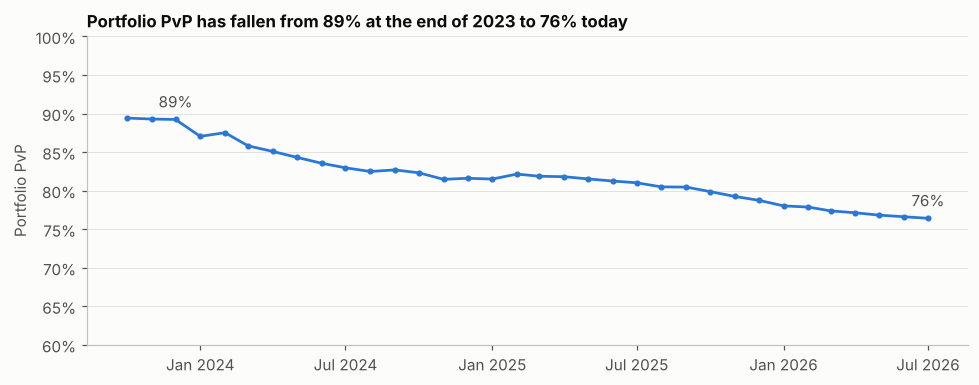

In [14]:
rows = []
for i, month in enumerate(MONTHS):
    month_end = month.to_timestamp(how="end").normalize()
    live = (portfolio["purchase_date"] <= month_end).to_numpy()
    due_m = due_at(portfolio, (month_end - portfolio["purchase_date"]).dt.days.to_numpy())
    app_m = applied(cum_cash[:, i], due_m)
    rows.append({"month": month, "contracts": live.sum(), "due": due_m[live].sum(), "applied": app_m[live].sum()})
pvp_series = pd.DataFrame(rows).set_index("month")
pvp_series["PvP"] = pvp_series["applied"] / pvp_series["due"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(pvp_series.index.to_timestamp(), pvp_series["PvP"], color=BLUE, marker="o", markersize=3)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Portfolio PvP")
ax.set_title("Portfolio PvP has fallen from 89% at the end of 2023 to 76% today")
date_axis(ax)
for month in [MONTHS[2], MONTHS[-1]]:
    ax.annotate(f"{pvp_series.loc[month, 'PvP']:.0%}", (month.to_timestamp(), pvp_series.loc[month, "PvP"]),
                textcoords="offset points", xytext=(0, 8), ha="center", color=INK2)
fig.tight_layout()
savefig(fig, "fig2_portfolio_pvp")
plt.show()

Portfolio PvP is **76.4%** today. One caution: a falling portfolio PvP is partly expected, because PvP dips during
the middle of each contract (late payers fall behind and catch up after the term ends), and a young portfolio
has more contracts in that middle stretch. To see whether customers really pay worse, I need to compare cohorts at the
same point in their term. That is the next section.

## 5. Cohorts at the same stage of the term (vintage curves)

For each contract I measure PvP at every 5% of its own term (5%, 10%, … 200%), add amounts within quarterly sales
cohorts, and show a point only when at least 100 contracts **and at least half of the cohort's financed amount** have
reached it. Without the second rule, the late points of young cohorts would show only their short-term products. The left panel is all products. The
right panel is model Z17 alone (one product, one 406-day term), so a change in product mix cannot cause what it shows.

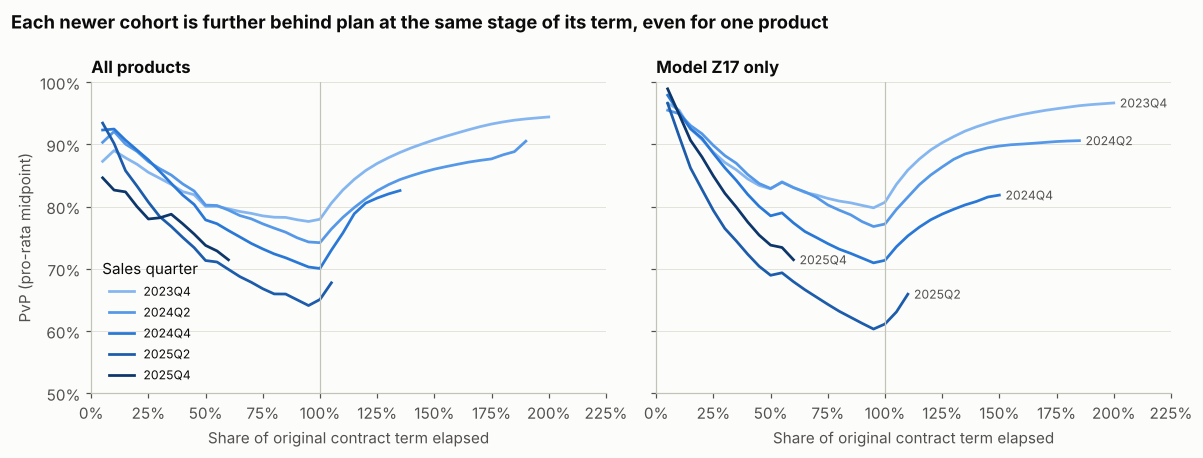

In [15]:
GRID_STEPS = np.round(np.arange(0.05, 2.0001, 0.05), 2)
grid_measures = {k: measure_at(k * portfolio["term_days"].to_numpy()) for k in GRID_STEPS}


def vintage_table(mask=None, by="cohort_q", min_share=0.5):
    frame = portfolio if mask is None else portfolio.loc[mask]
    cohort_financed = frame.groupby(by)["amount_financed"].sum()
    out = {}
    for k, measured in grid_measures.items():
        s = summarize(measured, by, frame)
        reached = (measured.loc[measured["eligible"], ["contract_id"]]
                   .merge(frame[["contract_id", by, "amount_financed"]], on="contract_id")
                   .groupby(by)["amount_financed"].sum())
        share = (reached / cohort_financed).reindex(s.index)
        out[k] = s["pvp_mid"].where((s["contracts"] >= MIN_COHORT_SIZE) & (share >= min_share))
    return pd.DataFrame(out)


vintage_all = vintage_table()
vintage_z17 = vintage_table(portfolio["model_code"] == "Z17")
show_q = [pd.Period(q) for q in ["2023Q4", "2024Q2", "2024Q4", "2025Q2", "2025Q4"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, table, title in [(axes[0], vintage_all, "All products"), (axes[1], vintage_z17, "Model Z17 only")]:
    for colour, q in zip(RAMP5, show_q):
        series = table.loc[q].dropna()
        ax.plot(series.index, series.to_numpy(), color=colour, label=str(q))
        if ax is axes[1]:
            ax.annotate(str(q), (series.index[-1], series.iloc[-1]), textcoords="offset points", xytext=(4, 0),
                        va="center", fontsize=8, color=INK2)
    ax.axvline(1.0, color=AXIS, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Share of original contract term elapsed")
    ax.xaxis.set_major_formatter(pct)
    ax.set_xlim(0, 2.25)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_ylabel("PvP (pro-rata midpoint)")
axes[0].legend(title="Sales quarter", loc="lower left", fontsize=8)
fig.suptitle("Each newer cohort is further behind plan at the same stage of its term, even for one product",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig3_vintage_curves")
plt.show()

In [16]:
checkpoints = [0.3, 0.5, 0.7, 0.9, 1.0, 1.5, 2.0]
display(Markdown("**PvP at the same stage of the term, model Z17 (cohorts with ≥ 100 contracts)**"))
display(save_table(vintage_z17[checkpoints].dropna(how="all"), "vintage_z17"))
display(Markdown("**PvP at the same stage of the term, all products**"))
display(save_table(vintage_all[checkpoints].dropna(how="all"), "vintage_all"))

**PvP at the same stage of the term, model Z17 (cohorts with ≥ 100 contracts)**

,0.300,0.500,0.700,0.900,1.000,1.500,2.000
cohort_q,,,,,,,
2023Q4,0.871,0.828,0.819,0.802,0.807,0.940,0.967
2024Q1,0.816,0.762,0.761,0.738,0.741,0.872,0.916
2024Q2,0.882,0.829,0.815,0.776,0.772,0.897,NaN
2024Q3,0.868,0.809,0.772,0.730,0.728,0.842,NaN
2024Q4,0.862,0.785,0.750,0.717,0.714,0.818,NaN
2025Q1,0.811,0.733,0.697,0.660,0.655,NaN,NaN
2025Q2,0.765,0.690,0.655,0.612,0.611,NaN,NaN
2025Q3,0.765,0.690,0.652,NaN,NaN,NaN,NaN
2025Q4,0.821,0.738,NaN,NaN,NaN,NaN,NaN


**PvP at the same stage of the term, all products**

,0.300,0.500,0.700,0.900,1.000,1.500,2.000
cohort_q,,,,,,,
2023Q4,0.845,0.800,0.789,0.779,0.780,0.907,0.944
2024Q1,0.837,0.785,0.767,0.751,0.746,0.873,0.911
2024Q2,0.861,0.802,0.780,0.750,0.742,0.860,NaN
2024Q3,0.857,0.792,0.755,0.722,0.713,NaN,NaN
2024Q4,0.856,0.779,0.741,0.710,0.700,NaN,NaN
2025Q1,0.813,0.737,0.700,0.673,0.684,NaN,NaN
2025Q2,0.784,0.713,0.678,0.650,0.651,NaN,NaN
2025Q3,0.777,0.715,0.680,NaN,NaN,NaN,NaN
2025Q4,0.782,0.738,NaN,NaN,NaN,NaN,NaN


This is the most important result in the notebook.

- **Same product, same stage, much worse.** At 90% of the term, Z17 cohorts sold in Q4 2023 had paid about **80%** of
  what was due. Cohorts sold in Q2–Q3 2025 had paid about **60–61%**. Z15, Z11 and Z37 show the same decline (table
  below), so this is not a product-mix effect.
- **The curve shape shows how this business collects.** PvP falls through the term as some customers fall behind,
  then rises after 100% of term as late payers catch up (the lockout makes them pay to use the device). The oldest
  cohorts end near **94–97%** at twice the term.
- **Q4 2025 sales are a little better** than Q2–Q3 2025 at the same stage (Z17: 82% against 77% at 30% of term,
  74% against 69% at 50%). But day-90 results for 2026 sales are back down (Section 6), so there is no clear turn yet.

In [17]:
other_models = {}
for model in ["Z15", "Z11", "Z37"]:
    table = vintage_table(portfolio["model_code"] == model)[[0.5, 0.9]].dropna(how="all")
    other_models[model] = table
display(Markdown("**PvP at 50% and 90% of term for the other main models (cohorts with ≥ 100 contracts)**"))
display(save_table(pd.concat(other_models, axis=1), "vintage_other_models"))

**PvP at 50% and 90% of term for the other main models (cohorts with ≥ 100 contracts)**

Z15         Z11         Z37      
         0.500 0.900 0.500 0.900 0.500 0.900
cohort_q                                    
2023Q4   0.751 0.729   NaN   NaN   NaN   NaN
2024Q1   0.760 0.726 0.778 0.737   NaN   NaN
2024Q2   0.764 0.705 0.783 0.727   NaN   NaN
2024Q3   0.761 0.687 0.761 0.691   NaN   NaN
2024Q4   0.742 0.665   NaN   NaN   NaN   NaN
2025Q1   0.693 0.616   NaN   NaN 0.754 0.686
2025Q2   0.681   NaN   NaN   NaN 0.707 0.633
2025Q3     NaN   NaN   NaN   NaN 0.721   NaN
2025Q4     NaN   NaN   NaN   NaN 0.725   NaN

## 6. KPI 3: repayment at day 90 for every monthly cohort

The TA showed day-90 bounds for Z17 in 2024. Here are all products and all monthly cohorts. The shaded band is the
timing range (lower = cutoff-month cash excluded, upper = included). The line is the pro-rata midpoint.

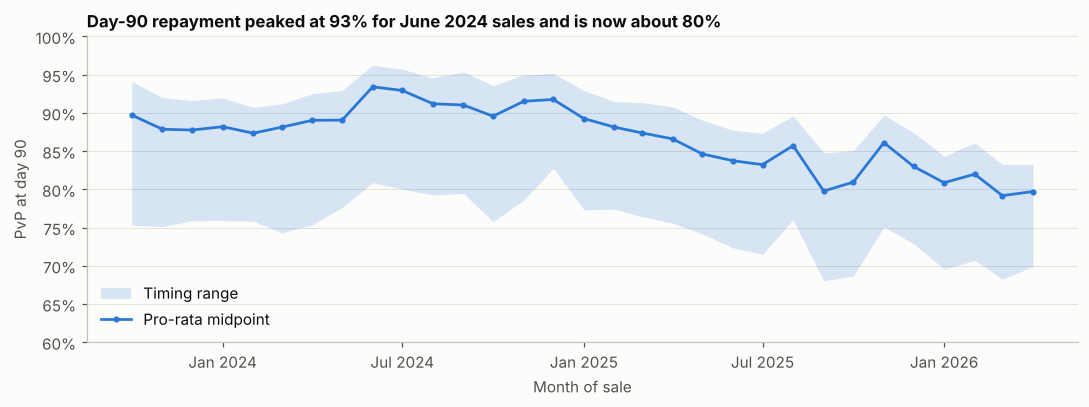

Whole portfolio, day 90: lower 75.0%, midpoint 86.5%, upper 90.3%  (23,765 contracts)


In [18]:
d90 = summarize(m90, "cohort")
d90 = d90.loc[d90["contracts"] >= MIN_COHORT_SIZE]
fig, ax = plt.subplots(figsize=(10, 3.8))
xt = d90.index.to_timestamp()
ax.fill_between(xt, d90["pvp_lower"], d90["pvp_upper"], color=BLUE, alpha=0.18, linewidth=0, label="Timing range")
ax.plot(xt, d90["pvp_mid"], color=BLUE, marker="o", markersize=3, label="Pro-rata midpoint")
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("PvP at day 90")
ax.set_xlabel("Month of sale")
ax.set_title("Day-90 repayment peaked at 93% for June 2024 sales and is now about 80%")
date_axis(ax)
ax.legend(loc="lower left")
fig.tight_layout()
savefig(fig, "fig4_day90_by_cohort")
plt.show()

eligible90 = m90.loc[m90["eligible"]]
print("Whole portfolio, day 90: lower {:.1%}, midpoint {:.1%}, upper {:.1%}  ({:,} contracts)".format(
    eligible90.applied_lower.sum() / eligible90.due.sum(), eligible90.applied_mid.sum() / eligible90.due.sum(),
    eligible90.applied_upper.sum() / eligible90.due.sum(), len(eligible90)))

The share of customers who start badly has also grown. Below is the share of each quarter's contracts with day-90
PvP under 75% (midpoint):

In [19]:
contract_90 = m90.assign(rate=m90["applied_mid"] / m90["due"]).merge(portfolio[["contract_id", "cohort_q"]], on="contract_id")
weak_start = contract_90.loc[contract_90["eligible"]].groupby("cohort_q")["rate"].apply(lambda r: (r < 0.75).mean())
display(save_table(weak_start.to_frame("share under 75% at day 90").T, "weak_start_share"))

cohort_q,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
share under 75% at day 90,0.152,0.196,0.152,0.118,0.118,0.191,0.252,0.263,0.208,0.243,0.239


On the midpoint, day-90 PvP runs from 93% (June 2024 sales) down to about 79–80% (March–April 2026 sales). That is
inside the GOGLA range ("leading results near 100%, some below 60%"). But the trend is down, and **the share of
customers below 75% at day 90 has doubled**, from about 12% of H2 2024 sales to 21–26% of sales since Q2 2025.

## 7. KPIs 4–5: repayment and ownership at twice the term, plus earlier milestones

Twice-term is the industry outcome measure. But only 4,825 contracts have reached it, and they are not a fair sample
of the book: they are the oldest sales (Q4 2023 to Q2 2024) plus short-term products (105–196 days, ~20% deposits)
sold later. GOGLA allows 1× and 1.5× term as earlier milestones (Technical Guide p. 11), and many more contracts have
reached those.

In [20]:
milestones = {"Day 90": m90, "1× term": measure_at(portfolio["term_days"].to_numpy()),
              "1.5× term": measure_at(1.5 * portfolio["term_days"].to_numpy()), "2× term": m2x}
overall = []
for name, measured in milestones.items():
    e = measured.loc[measured["eligible"]]
    overall.append({"milestone": name, "contracts": len(e),
                    "PvP lower": e.applied_lower.sum() / e.due.sum(), "PvP upper": e.applied_upper.sum() / e.due.sum(),
                    "ownership (count)": e.owned.mean()})
overall = pd.DataFrame(overall).set_index("milestone")
display(save_table(overall, "milestones_overall"))

by_milestone = pd.concat({name: summarize(measured, "cohort_q")[["contracts", "pvp_lower", "pvp_upper", "ownership"]]
                          for name, measured in list(milestones.items())[1:]}, axis=1)
display(save_table(by_milestone, "milestones_by_quarter"))

,contracts,PvP lower,PvP upper,ownership (count)
milestone,,,,
Day 90,23765,0.750,0.903,0.004
1× term,14994,0.691,0.729,0.173
1.5× term,7790,0.874,0.883,0.682
2× term,4825,0.934,0.937,0.848


1× term                               1.5× term                                 2× term                              
         contracts pvp_lower pvp_upper ownership contracts pvp_lower pvp_upper ownership contracts pvp_lower pvp_upper ownership
cohort_q                                                                                                                        
2023Q4        1871     0.754     0.802     0.243      1871     0.902     0.912     0.751 1,869.000     0.943     0.945     0.871
2024Q1        1110     0.728     0.766     0.193      1110     0.867     0.878     0.651 1,029.000     0.909     0.912     0.784
2024Q2        1779     0.721     0.761     0.177      1779     0.857     0.863     0.625   757.000     0.939     0.943     0.795
2024Q3        2192     0.693     0.727     0.185      1338     0.874     0.880     0.652   270.000     0.963     0.967     0.919
2024Q4        2443     0.682     0.716     0.154       957     0.852     0.861     0.617   224.000     0.947     0.951     0.897
2025Q1        2870     0.661     0.700     0.134       254     0.946     0.965     0.866   254.000     0.978     0.980     0.969
2025Q2        2458     0.628     0.667     0.144       258     0.947     0.960     0.880   258.000     0.969     0.971     0.930
2025Q3         198     0.738     0.834     0.374       196     0.854     0.870     0.730   151.000     0.866     0.876     0.755
2025Q4          56     0.692     0.751     0.357        26     0.788     0.811     0.654    13.000     0.708     0.715     0.692
2026Q1          17     0.674     0.777     0.235         1     1.000     1.000     1.000       NaN       NaN       NaN       NaN

In [21]:
twice = m2x.loc[m2x["eligible"]].merge(portfolio, on="contract_id")
twice["product group"] = np.where(twice["term_days"] <= 200, "Short-term products (≤200-day term)",
                                  np.where(twice["model_code"].isin(["Z17", "Z11", "Z15"]), twice["model_code"], "Other models"))
comp = twice.groupby("product group").agg(contracts=("due", "size"), first_sale=("purchase_date", "min"),
                                         last_sale=("purchase_date", "max"), due=("due", "sum"),
                                         applied=("applied_mid", "sum"), owned=("owned", "mean"),
                                         median_deposit=("deposit_share", "median"))
comp["PvP@2x"] = comp["applied"] / comp["due"]
display(Markdown("**Who has reached twice-term?**"))
display(save_table(comp.drop(columns=["due", "applied"]), "twice_term_composition"))

**Who has reached twice-term?**

,contracts,first_sale,last_sale,owned,median_deposit,PvP@2x
product group,,,,,,
Other models,195,2023-10-01,2024-07-09,0.846,0.094,0.964
Short-term products (≤200-day term),1693,2023-10-01,2025-12-14,0.913,0.184,0.959
Z11,839,2024-01-20,2024-05-10,0.764,0.049,0.901
Z15,746,2023-10-01,2024-04-29,0.751,0.082,0.905
Z17,1352,2023-10-07,2024-05-07,0.875,0.068,0.961


In [22]:
bench = pd.DataFrame({
    "This company": [overall.loc["2× term", "PvP lower"], overall.loc["2× term", "ownership (count)"]],
    "GOGLA overall": [BENCH_PVP_2X["Overall sample"], BENCH_OR_2X],
    "GOGLA West Africa": [BENCH_PVP_2X["West Africa"], np.nan],
}, index=["Repayment at 2× term", "Ownership at 2× term"])
display(save_table(bench, "benchmarks"))

,This company,GOGLA overall,GOGLA West Africa
Repayment at 2× term,0.934,0.720,0.770
Ownership at 2× term,0.848,0.780,NaN


- **The finished contracts are good.** PvP at twice-term is **93.4–93.7%** and ownership **84.8%**, above GOGLA's
  historical averages (72% repayment, 77% for West Africa; 78% ownership). This matches the lecture's Z17 examples.
- **That is not what the investor would be buying.** These finished contracts are 19% of the book by count and come
  mostly from the best period. At 1× term, which 15,000 contracts have reached, PvP falls steadily from **75–80%** for Q4 2023
  sales to **63–67%** for Q2 2025 sales, and ownership at 1× from 24% to 14%.
- Benchmarks are context, not a hurdle. They use a different KPI version (pre-June 2026), unweighted country-firm
  averages, other product mixes and other subsidy settings, and my numbers are conditional on the allocation
  assumption.

## 8. Does day 90 predict the final outcome here?

The lecture's GOGLA illustration links day-90 PvP to the twice-term result, with a warning to calibrate it to the
company. The files let me check that, first for individual contracts and then for whole cohorts.

In [23]:
early = pd.DataFrame({"contract_id": portfolio["contract_id"], "status": portfolio["contract_status"],
                      "day90": m90["applied_mid"] / m90["due"], "eligible_2x": m2x["eligible"],
                      "applied_2x": m2x["applied_mid"], "due_2x": m2x["due"], "owned_2x": m2x["owned"]})
early["day-90 band"] = pd.cut(early["day90"], [-0.01, 0.5, 0.75, 0.9, 0.9999, 1.0],
                              labels=["<50%", "50-75%", "75-90%", "90-<100%", "100%"])
cal = early.loc[early["eligible_2x"]].groupby("day-90 band", observed=True).agg(
    contracts=("due_2x", "size"), applied=("applied_2x", "sum"), due=("due_2x", "sum"),
    ownership_2x=("owned_2x", "mean"), repossessed=("status", lambda s: (s == "REPOSSESSED").mean()))
cal["PvP@2x"] = cal["applied"] / cal["due"]
display(Markdown("**Contracts that reached twice-term, grouped by their own day-90 PvP**"))
display(save_table(cal[["contracts", "PvP@2x", "ownership_2x", "repossessed"]], "day90_calibration_contract"))

**Contracts that reached twice-term, grouped by their own day-90 PvP**

,contracts,PvP@2x,ownership_2x,repossessed
day-90 band,,,,
<50%,194,0.557,0.294,0.227
50-75%,620,0.815,0.590,0.037
75-90%,857,0.930,0.782,0.006
90-<100%,1077,0.976,0.914,0.004
100%,2077,0.992,0.971,0.000


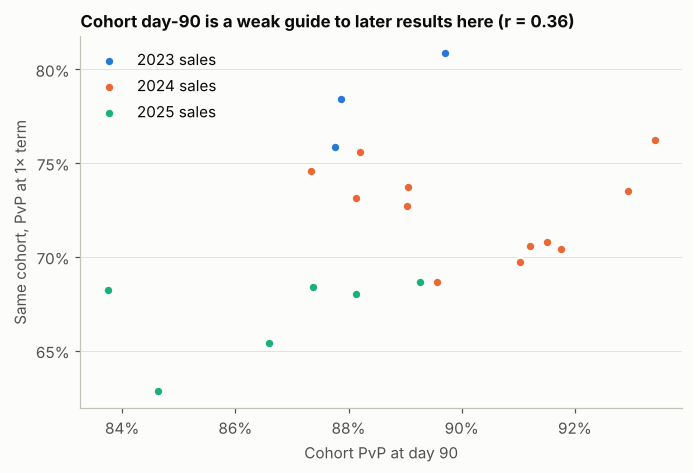

In [24]:
cohort_link = pd.DataFrame({"day90": summarize(m90, "cohort")["pvp_mid"],
                            "pvp_1x": summarize(milestones["1× term"], "cohort")["pvp_mid"],
                            "n_1x": summarize(milestones["1× term"], "cohort")["contracts"]}).dropna()
cohort_link = cohort_link.loc[cohort_link["n_1x"] >= MIN_COHORT_SIZE]
r = cohort_link["day90"].corr(cohort_link["pvp_1x"])
fig, ax = plt.subplots(figsize=(6.4, 4.4))
year_colour = {2023: BLUE, 2024: ORANGE, 2025: AQUA}
for year, colour in year_colour.items():
    sel = cohort_link.index.year == year
    ax.scatter(cohort_link.loc[sel, "day90"], cohort_link.loc[sel, "pvp_1x"], s=40, color=colour,
               edgecolor=SURFACE, linewidth=1.5, label=f"{year} sales", zorder=3)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.xaxis.set_major_locator(MultipleLocator(0.02))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_xlabel("Cohort PvP at day 90")
ax.set_ylabel("Same cohort, PvP at 1× term")
ax.set_title(f"Cohort day-90 is a weak guide to later results here (r = {r:.2f})")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "fig5_day90_vs_1x")
plt.show()

- **For one contract, day 90 says a lot.** Customers below 50% at day 90 reached only 56% repayment and 29%
  ownership at twice-term, and 23% were repossessed. Customers at 100% on day 90 reached 99% and 97%.
- **For cohorts, day 90 is a weak guide here.** Mid-2024 cohorts had the best day-90 results (91–93%) but are well
  behind the 2023 cohorts at 1× term. They slipped later in the term, during 2025. So for this company GOGLA's
  illustrative day-90-to-outcome relationship would have been too optimistic. An investor should watch cohorts at
  50% and 100% of term, not only day 90.

## 9. What is driving the decline?

### 9.1 A calendar-time drop that hit every cohort at once

For contracts between 15% and 90% of their term, I compare the cash received in each calendar month with the
instalments that fell due in that month. If all cohorts weaken in the same months, the cause is something that
hit everyone at once (prices, incomes, a policy or operations change), not only weaker new customers.

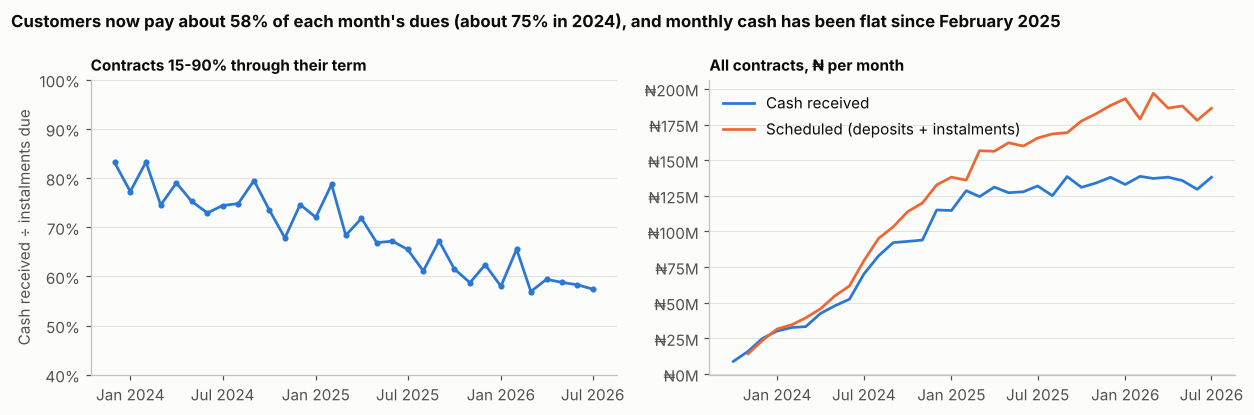

In [25]:
pay_rows = []
for i, month in enumerate(MONTHS[1:], start=1):
    month_end = month.to_timestamp(how="end").normalize()
    prev_end = MONTHS[i - 1].to_timestamp(how="end").normalize()
    t_now = (month_end - portfolio["purchase_date"]).dt.days.to_numpy()
    t_prev = (prev_end - portfolio["purchase_date"]).dt.days.to_numpy()
    elapsed = t_now / portfolio["term_days"].to_numpy()
    window = (t_prev >= 0) & (elapsed > 0.15) & (elapsed < 0.90)
    due_in_month = due_at(portfolio, t_now) - due_at(portfolio, t_prev)
    cash_in_month = cum_cash[:, i] - cum_cash[:, i - 1]
    pay_rows.append({"month": month, "contracts": window.sum(), "cash": cash_in_month[window].sum(),
                     "due": due_in_month[window].sum(),
                     "scheduled_all": (due_at(portfolio, t_now) - due_at(portfolio, t_prev)).sum()
                     + portfolio.loc[portfolio["cohort"] == month, "deposit"].sum()})
pay = pd.DataFrame(pay_rows).set_index("month")
pay["pay rate"] = pay["cash"] / pay["due"]
pay = pay.loc[pay["contracts"] >= 500]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(pay.index.to_timestamp(), pay["pay rate"], color=BLUE, marker="o", markersize=3)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylim(0.4, 1.0)
axes[0].set_ylabel("Cash received ÷ instalments due")
axes[0].set_title("Contracts 15-90% through their term", fontsize=10)
date_axis(axes[0])
total = pd.DataFrame({"Receipts (all contracts)": monthly_cash.sum().to_numpy() / 1e6}, index=MONTHS.to_timestamp())
scheduled = pd.DataFrame(pay_rows).set_index("month")["scheduled_all"] / 1e6
axes[1].plot(total.index, total.iloc[:, 0], color=BLUE, label="Cash received")
axes[1].plot(scheduled.index.to_timestamp(), scheduled, color=ORANGE, label="Scheduled (deposits + instalments)")
axes[1].yaxis.set_major_formatter(naira_m)
axes[1].set_title("All contracts, ₦ per month", fontsize=10)
axes[1].legend(loc="upper left")
date_axis(axes[1])
fig.suptitle("Customers now pay about 58% of each month's dues (about 75% in 2024), and monthly cash has been flat "
             "since February 2025", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
savefig(fig, "fig6_calendar_pay_rate")
plt.show()

In [26]:
cohort_pay = []
for i, month in enumerate(MONTHS[1:], start=1):
    month_end = month.to_timestamp(how="end").normalize()
    prev_end = MONTHS[i - 1].to_timestamp(how="end").normalize()
    t_now = (month_end - portfolio["purchase_date"]).dt.days.to_numpy()
    t_prev = (prev_end - portfolio["purchase_date"]).dt.days.to_numpy()
    elapsed = t_now / portfolio["term_days"].to_numpy()
    window = (t_prev >= 0) & (elapsed > 0.15) & (elapsed < 0.90) & (portfolio["model_code"] == "Z17").to_numpy()
    frame = pd.DataFrame({"q": portfolio["cohort_q"], "cash": cum_cash[:, i] - cum_cash[:, i - 1],
                          "due": due_at(portfolio, t_now) - due_at(portfolio, t_prev)}).loc[window]
    g = frame.groupby("q").agg(cash=("cash", "sum"), due=("due", "sum"), n=("cash", "size"))
    g = g.loc[g["n"] >= MIN_COHORT_SIZE]
    for q, row in g.iterrows():
        cohort_pay.append({"month": str(month), "cohort": str(q), "rate": row.cash / row.due})
cohort_pay = pd.DataFrame(cohort_pay).pivot(index="month", columns="cohort", values="rate")
display(Markdown("**Z17 only: cash ÷ dues by calendar month (rows) and sales quarter (columns)**"))
display(save_table(cohort_pay.loc["2024-09":].round(2), "z17_pay_rate_calendar_by_cohort"))

**Z17 only: cash ÷ dues by calendar month (rows) and sales quarter (columns)**

cohort,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
month,,,,,,,,,,,
2024-09,0.810,0.790,0.930,0.850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-10,0.750,0.700,0.780,0.840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-11,0.670,0.690,0.740,0.740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-12,NaN,0.690,0.750,0.780,0.800,NaN,NaN,NaN,NaN,NaN,NaN
2025-01,NaN,NaN,0.660,0.720,0.790,NaN,NaN,NaN,NaN,NaN,NaN
2025-02,NaN,NaN,0.810,0.800,0.890,NaN,NaN,NaN,NaN,NaN,NaN
2025-03,NaN,NaN,0.670,0.630,0.720,0.760,NaN,NaN,NaN,NaN,NaN
2025-04,NaN,NaN,0.700,0.660,0.730,0.770,NaN,NaN,NaN,NaN,NaN
2025-05,NaN,NaN,0.650,0.610,0.650,0.690,NaN,NaN,NaN,NaN,NaN


The pay rate fell from about 75% in 2024 to about 58% in 2026. The Z17 table shows that in March–May 2025
**every cohort fell at the same time** (for example Q4 2024 sales went from 0.89 to 0.65 in three months). Each new
cohort also starts lower than the one before. So the decline has two causes: something in the environment from early
2025, and weaker new sales. The data cannot say what the environmental cause was. Candidates for the committee to ask
about are household incomes and inflation in Nigeria, price changes, the move to agent-only sales, and changes in
collections or lockout policy. Most new cohorts also start lower than the one before (Q4 2025 is the exception).

Total cash collected has been flat at about ₦125–140M a month for 18 months, while the amount scheduled to come in
kept rising.

### 9.2 Channel, region, deposit and product, compared fairly

Raw segment averages mix in sales month and product (for example, staff sold more in 2025, a weak period). I
regress each contract's day-90 PvP (midpoint) on the segment while holding the **sales month** and **model** fixed,
weighting by amount due (so the result describes ₦, like the KPI), with standard errors clustered by sales month.
This makes the comparison fairer, but it is still not causal: who buys from an agent, and why, is not observed.

In [27]:
reg = portfolio.merge(m90[["contract_id", "eligible", "due", "applied_mid"]], on="contract_id")
reg = reg.loc[reg["eligible"]].copy()
reg["y"] = reg["applied_mid"] / reg["due"]
reg["cohort_s"] = reg["cohort"].astype(str)
reg["model_f"] = np.where(reg["model_code"].map(reg["model_code"].value_counts()) >= MIN_COHORT_SIZE, reg["model_code"], "small models")
reg["deposit_band"] = pd.cut(reg["deposit_share"], [-0.001, 0.0001, 0.05, 0.10, 1.0],
                             labels=["0%", "0-5%", "5-10%", ">10%"]).astype(str)


def fit(formula, data):
    groups = data["cohort_s"].astype("category").cat.codes
    return smf.wls(formula, data=data, weights=data["due"]).fit(cov_type="cluster", cov_kwds={"groups": groups})


def coef_table(result, pattern, label):
    est = result.params.filter(regex=pattern)
    se = result.bse.filter(regex=pattern)
    names = [n.split("[T.")[-1].rstrip("]") for n in est.index]
    return pd.DataFrame({"model": label, "vs": "", "difference (pts)": 100 * est.to_numpy(),
                         "95% CI low": 100 * (est - 1.96 * se).to_numpy(), "95% CI high": 100 * (est + 1.96 * se).to_numpy()},
                        index=names)


r_channel = fit("y ~ C(seller, Treatment('staff')) + C(region_f, Treatment('Region A')) + C(cohort_s) + C(model_f)", reg)
r_deposit = fit("y ~ C(deposit_band, Treatment('0-5%')) + np.log(cash_price) + C(seller) + C(cohort_s)", reg)
effects = pd.concat([
    coef_table(r_channel, "seller", "channel, vs staff").assign(vs="staff"),
    coef_table(r_channel, "region", "region, vs Region A").assign(vs="Region A"),
    coef_table(r_deposit, "deposit_band", "deposit, vs 0-5%").assign(vs="0-5% deposit"),
])
display(Markdown(f"**Adjusted differences in day-90 PvP, percentage points** ({int(r_channel.nobs):,} contracts)"))
display(save_table(effects.drop(columns="model").round(1), "adjusted_differences_day90"))

**Adjusted differences in day-90 PvP, percentage points** (23,765 contracts)

,vs,difference (pts),95% CI low,95% CI high
Unknown,staff,5.600,2.700,8.600
agent,staff,9.000,6.700,11.300
Region B,Region A,-3.500,-5.800,-1.200
Region C,Region A,-5.700,-13.900,2.400
Unknown,Region A,-2.000,-5.300,1.300
0%,0-5% deposit,-15.000,-19.800,-10.200
5-10%,0-5% deposit,-4.700,-8.300,-1.100
>10%,0-5% deposit,-3.000,-5.800,-0.200


In [28]:
m1x = milestones["1× term"]
reg1 = portfolio.merge(m1x[["contract_id", "eligible", "due", "applied_mid", "owned"]], on="contract_id")
reg1 = reg1.loc[reg1["eligible"]].copy()
reg1["y"] = reg1["applied_mid"] / reg1["due"]
reg1["cohort_s"] = reg1["cohort"].astype(str)
reg1["model_f"] = np.where(reg1["model_code"].map(reg1["model_code"].value_counts()) >= MIN_COHORT_SIZE, reg1["model_code"], "small models")
r_channel_1x = fit("y ~ C(seller, Treatment('staff')) + C(region_f, Treatment('Region A')) + C(cohort_s) + C(model_f)", reg1)
display(Markdown(f"**Same model for PvP at 1× term** ({int(r_channel_1x.nobs):,} contracts)"))
display(coef_table(r_channel_1x, "seller|region", "").drop(columns=["model", "vs"]).round(1))
raw_channel = reg1.groupby("seller").agg(contracts=("y", "size"), applied=("applied_mid", "sum"), due=("due", "sum"),
                                         ownership_1x=("owned", "mean"))
raw_channel["PvP@1x"] = raw_channel["applied"] / raw_channel["due"]
display(raw_channel[["contracts", "PvP@1x", "ownership_1x"]])

z17_90 = reg.loc[reg["model_code"] == "Z17"].groupby(["cohort_q", "seller"])[["applied_mid", "due"]].sum()
z17_channel = (z17_90["applied_mid"] / z17_90["due"]).unstack()
z17_n = reg.loc[reg["model_code"] == "Z17"].groupby(["cohort_q", "seller"]).size().unstack()
display(Markdown("**Z17 day-90 PvP by sales quarter and channel (cells with ≥ 50 contracts)**"))
display(save_table(z17_channel.where(z17_n >= 50)[["agent", "staff"]].dropna(how="all"), "z17_channel_day90"))

**Same model for PvP at 1× term** (14,994 contracts)

,difference (pts),95% CI low,95% CI high
Unknown,9.300,6.400,12.200
agent,10.800,9.000,12.700
Region B,-4.200,-6.500,-2.000
Region C,-0.400,-7.500,6.700
Unknown,12.500,7.300,17.600


,contracts,PvP@1x,ownership_1x
seller,,,
Unknown,1438,0.807,0.304
agent,8558,0.766,0.216
staff,4998,0.609,0.063


**Z17 day-90 PvP by sales quarter and channel (cells with ≥ 50 contracts)**

seller,agent,staff
cohort_q,,
2023Q4,0.920,0.853
2024Q1,0.882,NaN
2024Q2,0.948,NaN
2024Q3,0.942,0.857
2024Q4,0.937,0.877
2025Q1,0.906,0.848
2025Q2,0.852,0.789
2025Q3,0.861,0.750
2025Q4,0.907,0.730


- **Agents beat staff by about 9 points at day 90 and 11 points at 1× term**, with the same product, sales month and
  region. Ownership at 1× term is 22% for agent sales against 6% for staff. For Z17 the gap appears in every sales
  quarter (table above), as the TA's example showed for 2024. The company has already moved to agent-only sales, which should help. But agents earn
  commission, so the committee should ask whether their customers are screened differently, or whether early
  repayments are being propped up.
- **Region B is about 3.5 points below Region A**, and Region C about 6 points below (Region C has only 270 contracts, so
  that estimate is uncertain).
- **Zero deposit is the clearest risk signal: −15 points** at day 90 against a 0–5% deposit, after controls.
- Among contracts that do have a deposit, a bigger one is *not* linked to better day-90 repayment here (−3 to −5
  points). Deposit share mostly reflects which product was sold (5–10% for the larger systems, ~20% for short-term
  products), and this data cannot separate the two. Over the whole term the raw outcomes do follow the deposit
  (Section 10), but that also mixes in product and term length.

### 9.3 The new large and zero-deposit products

These products are now more than half the money lent, so their early results matter most for the future book.
Contracts sold since July 2025 at day 90:

In [29]:
recent_sales = portfolio["purchase_date"] >= "2025-07-01"
recent90 = m90.loc[m90["eligible"]].merge(portfolio.loc[recent_sales], on="contract_id")
by_model = recent90.groupby("model_code").agg(
    contracts=("due", "size"), tier=("tier", "first"), price_k=("cash_price", lambda s: s.median() / 1e3),
    deposit=("deposit_share", "median"), due=("due", "sum"), applied=("applied_mid", "sum"),
    repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()))
by_model["PvP@90"] = by_model["applied"] / by_model["due"]
by_model = by_model.loc[by_model["contracts"] >= 50].sort_values("due", ascending=False)
display(save_table(by_model.drop(columns=["due", "applied"]), "recent_products_day90"))
grp = recent90.assign(group=np.where(recent90["tier_group"] == "Tier 4-5", "Tier 4-5", "Tier 1-3 and unknown")).groupby("group")
print((grp["applied_mid"].sum() / grp["due"].sum()).round(3).to_dict())

,contracts,tier,price_k,deposit,repossessed,PvP@90
model_code,,,,,,
Z37,3300,Tier 2,146.768,0.034,0.047,0.867
Z17,2980,Tier 1,114.077,0.039,0.047,0.850
Z12,376,Tier 4,422.538,0.073,0.056,0.658
Z04,67,Tier 5,"2,464.193",0.066,0.015,0.930
Z34,116,Tier 5,"2,116.562",0.000,0.147,0.682
Z29,65,Tier 5,"1,584.452",0.159,0.000,0.885
Z26,128,Tier 4,476.216,0.067,0.078,0.724
Z39,113,Tier 3,290.640,0.075,0.018,0.864
Z18,60,Tier 2,158.233,0.166,0.033,0.784


{'Tier 1-3 and unknown': 0.854, 'Tier 4-5': 0.777}


Since mid-2025, Tier 4–5 contracts reached **78%** at day 90 against **85%** for smaller systems. Z12 (66%), Z34
(68%, zero deposit, 15% already repossessed) and Z26 (72%) are the weakest. Z04 (93%) and Z29 (89%, 16% deposit)
show that large systems can work with a real deposit. With so much of the new lending in large systems, their
repayment will decide the next two years.

## 10. Customers and energy access: lockouts, repossessions and ownership

Payments are not energy, but the lockout is the point where a missed payment becomes a household without light or
power. `days_locked` is cumulative locked days to the 10 August snapshot (the TA flags that its exact endpoint needs
confirming), so I treat it as approximate.

In [30]:
portfolio["days_since_sale"] = (STATUS_DATE - portfolio["purchase_date"]).dt.days.clip(lower=1)
lock = portfolio.groupby("cohort_q").agg(contracts=("contract_id", "size"),
                                         locked_days=("days_locked", "sum"), days=("days_since_sale", "sum"),
                                         repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()),
                                         owned=("contract_status", lambda s: (s == "PAID_OFF").mean()))
lock["share of days locked"] = lock["locked_days"] / lock["days"]
lock["locked now (of active)"] = portfolio.loc[active].groupby("cohort_q")["contract_status"].apply(lambda s: (s == "LOCKED").mean())
display(save_table(lock[["contracts", "share of days locked", "locked now (of active)", "repossessed", "owned"]], "lockouts_by_quarter"))
by_status = portfolio.assign(share=portfolio["days_locked"] / portfolio["days_since_sale"]).groupby("contract_status")["share"].median()
print("Median share of days locked, by status:", by_status.round(3).to_dict())

dep_band_all = pd.cut(portfolio["deposit_share"], [-0.001, 0.0001, 0.05, 0.10, 0.20, 1.0], labels=["0%", "0-5%", "5-10%", "10-20%", ">20%"])
display(save_table(portfolio.groupby(dep_band_all, observed=True).agg(
    contracts=("contract_id", "size"), repossessed=("contract_status", lambda s: (s == "REPOSSESSED").mean()),
    paid_off=("contract_status", lambda s: (s == "PAID_OFF").mean())), "deposit_band_outcomes"))

,contracts,share of days locked,locked now (of active),repossessed,owned
cohort_q,,,,,
2023Q4,1871,0.152,0.976,0.008,0.901
2024Q1,1110,0.217,0.888,0.025,0.798
2024Q2,1779,0.230,0.939,0.037,0.734
2024Q3,2195,0.259,0.786,0.026,0.584
2024Q4,2457,0.275,0.745,0.029,0.515
2025Q1,3391,0.306,0.712,0.033,0.405
2025Q2,3246,0.310,0.620,0.051,0.248
2025Q3,2742,0.295,0.481,0.040,0.077
2025Q4,1894,0.248,0.395,0.052,0.025


Median share of days locked, by status: {'LOCKED': 0.519, 'ON': 0.114, 'PAID_OFF': 0.056, 'REPOSSESSED': 0.035}


,contracts,repossessed,paid_off
deposit_share,,,
0%,358,0.123,0.151
0-5%,14580,0.044,0.185
5-10%,8514,0.025,0.506
10-20%,1760,0.013,0.780
>20%,473,0.004,0.934


- **Half of active customers were locked out on 10 August** (8,140 of 15,885). Customers sold in Q1–Q3 2025 have spent
  about **30% of their days locked**, against 15% for Q4 2023 sales. Even customers who finished paying spent a median
  6% of their days locked.
- **Repossessions are rising even though newer cohorts have had less time**: 0.8% of Q4 2023 sales against 4–5.5% of
  Q2 2025 to Q1 2026 sales. Zero-deposit contracts: 12%.
- **8,875 households own their system outright** (35% of all contracts). For them, payment lockouts are over.
  Whether the system still works, and how much electricity it provides, is not in the data (Section 12).

## 11. Risk in today's open book

For active contracts (ON or LOCKED): outstanding = contract price − cash received. I show portfolio-at-risk in two
ways. "System" days uses the company's `payment_due_date`, which moves forward during lockouts. "Original schedule"
turns each contract's cumulative arrears into days of instalments. These are diagnostics, not GOGLA KPIs, and the
system measure mixes the 31 July balances with the 10 August due dates.

In [31]:
book = portfolio.loc[active].copy()
book["outstanding"] = (book["cash_price"] - book["ledger_total"]).clip(lower=0)
book["arrears"] = book["due_to_date"] - book["applied_now"]
book["arrears_days"] = book["arrears"] / (book["instalment"] / book["period_days"])
book["system_days"] = (STATUS_DATE - book["payment_due_date"]).dt.days.clip(lower=0)
par = pd.DataFrame({f"> {d} days": [book.loc[book["system_days"] > d, "outstanding"].sum() / book["outstanding"].sum(),
                                     book.loc[book["arrears_days"] > d, "outstanding"].sum() / book["outstanding"].sum()]
                    for d in [30, 90, 180]}, index=["PAR, system days past due", "PAR, original-schedule arrears"])
print(f"Active contracts {len(book):,}; outstanding ₦{book.outstanding.sum()/1e6:,.0f}M; "
      f"cumulative arrears ₦{book.arrears.sum()/1e6:,.0f}M")
display(save_table(par, "portfolio_at_risk"))

window_cash = payments.loc[payments["payment_month"] >= "2026-02-01"].groupby("contract_id")["amount_paid"].sum()
inactive = ((portfolio["purchase_date"] < "2026-02-01") & (portfolio["contract_status"] != "PAID_OFF")
            & (portfolio["contract_id"].map(window_cash).fillna(0) == 0))
inactive_active = inactive & active
print(f"No payment February-July 2026: {inactive.sum():,} contracts "
      f"({portfolio.loc[inactive, 'contract_status'].value_counts().to_dict()}); "
      f"active ones hold ₦{(portfolio.cash_price - portfolio.ledger_total).clip(lower=0)[inactive_active].sum()/1e6:,.0f}M "
      f"= {(portfolio.cash_price - portfolio.ledger_total).clip(lower=0)[inactive_active].sum()/book.outstanding.sum():.0%} of active outstanding")

Active contracts 15,885; outstanding ₦1,976M; cumulative arrears ₦806M


,> 30 days,> 90 days,> 180 days
"PAR, system days past due",0.302,0.204,0.138
"PAR, original-schedule arrears",0.611,0.439,0.269


No payment February-July 2026: 2,844 contracts ({'LOCKED': 2211, 'REPOSSESSED': 622, 'ON': 11}); active ones hold ₦251M = 13% of active outstanding


**₦1.98bn is outstanding on 15,885 active contracts.** About 30% of it is more than 30 system days late. Against the
original schedule, 61% is more than 30 days of instalments behind and 27% more than 180 days. 2,222 active
contracts (2,211 of them locked) paid nothing at all from February to July; they hold 13% of the outstanding balance. In a flexible PAYGo model,
arrears are partly normal, since customers pause and come back. But the trend in Sections 5–9 says these numbers are
getting worse.

## 12. Looking ahead: what will today's book eventually repay?

This is a projection, not a measurement, so I keep it simple and test it.

**Method.** I split each contract's progress into steps of 10% of its term. For each step and each repayment band
(PvP at the start of the step: <50%, 50–75%, 75–90%, 90–<100%, 100%), I estimate from history what share of the
*unpaid financed balance* gets collected during that step. Then I roll every open contract forward from where it
is today to twice its term. Paid-off contracts are complete. Repossessed contracts collect nothing more.

**Backtest.** I hide one cohort, estimate the rates from the others, and project the hidden cohort from an earlier
stage to 1× term, then compare with what actually happened.

In [32]:
STEPS = 20
grid10 = {k: measure_at(k / 10 * portfolio["term_days"].to_numpy()) for k in range(1, STEPS + 1)}
A = np.column_stack([np.zeros(len(portfolio))] + [np.nan_to_num(grid10[k]["applied_mid"].to_numpy()) for k in range(1, STEPS + 1)])
D = np.column_stack([np.zeros(len(portfolio))] + [grid10[k]["due"].to_numpy() for k in range(1, STEPS + 1)])
E = np.column_stack([np.ones(len(portfolio), bool)] + [grid10[k]["eligible"].to_numpy() for k in range(1, STEPS + 1)])
STEP_DATE = np.column_stack([portfolio["purchase_date"].to_numpy()] + [grid10[k]["cutoff"].to_numpy() for k in range(1, STEPS + 1)])
BAND_EDGES = [0.5, 0.75, 0.9, 0.9999]


def band_of(a, d):
    return np.digitize(np.where(d > 0, a / np.maximum(d, 1), 1.0), BAND_EDGES)


def collection_rates(mask, since=None):
    """Share of the unpaid financed balance collected in each step, by band; `since` keeps only steps ending after a date."""
    rates = np.full((STEPS + 1, 5), np.nan)
    for k in range(1, STEPS):
        ok = E[:, k + 1] & mask
        if since is not None:
            ok = ok & (STEP_DATE[:, k + 1] >= np.datetime64(since))
        b = band_of(A[ok, k], D[ok, k])
        unpaid, gain = financed[ok] - A[ok, k], A[ok, k + 1] - A[ok, k]
        for j in range(5):
            sel = b == j
            if sel.sum() >= 30 and unpaid[sel].sum() > 0:
                rates[k, j] = gain[sel].sum() / unpaid[sel].sum()
    return pd.DataFrame(rates).ffill().bfill().to_numpy()


def roll_forward(rates, start_step, start_applied, end_step=STEPS):
    a = start_applied.copy()
    for k in range(1, end_step):
        go = k >= start_step
        b = band_of(a, D[:, k])
        step_gain = rates[k, b] * (financed - a)
        a = np.where(go, np.minimum(a + step_gain, D[:, k + 1]), a)
    return a


rates_all = collection_rates(np.ones(len(portfolio), bool))
display(Markdown("**Share of the unpaid financed balance collected per 10%-of-term step, by repayment band at the start of the step**"))
display(save_table(pd.DataFrame(rates_all[1:STEPS], index=[f"{k*10}-{(k+1)*10}%" for k in range(1, STEPS)],
                                columns=["<50%", "50-75%", "75-90%", "90-<100%", "100%"]).iloc[::2], "collection_rates"))

**Share of the unpaid financed balance collected per 10%-of-term step, by repayment band at the start of the step**

,<50%,50-75%,75-90%,90-<100%,100%
10-20%,0.040,0.061,0.081,0.089,0.103
30-40%,0.023,0.057,0.092,0.120,0.138
50-60%,0.024,0.068,0.122,0.170,0.186
70-80%,0.025,0.084,0.174,0.272,0.337
90-100%,0.025,0.111,0.300,0.656,0.949
110-120%,0.022,0.105,0.368,0.856,1.000
130-140%,0.016,0.076,0.288,0.690,1.000
150-160%,0.009,0.069,0.215,0.662,0.740
170-180%,0.007,0.049,0.193,0.601,1.000
190-200%,0.005,0.040,0.153,0.514,1.000


In [33]:
backtest = []
for q in ["2024Q1", "2024Q3", "2024Q4", "2025Q1", "2025Q2"]:
    in_q = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    rates_loo = collection_rates(~in_q)
    test = in_q & E[:, 10]
    for k0 in [3, 5, 7]:
        projected = roll_forward(rates_loo, k0, A[:, k0], end_step=10)
        backtest.append({"cohort": q, "projected from": f"{k0*10}% of term", "target": "1× term", "contracts": test.sum(),
                         "projected": projected[test].sum() / financed[test].sum(),
                         "actual": A[test, 10].sum() / financed[test].sum()})
for q in ["2023Q4", "2024Q1", "2024Q2"]:
    in_q = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    test = in_q & E[:, 20]
    projected = roll_forward(collection_rates(~in_q), 10, A[:, 10], end_step=20)
    backtest.append({"cohort": q, "projected from": "100% of term", "target": "2× term", "contracts": test.sum(),
                     "projected": projected[test].sum() / financed[test].sum(),
                     "actual": A[test, 20].sum() / financed[test].sum()})
backtest = pd.DataFrame(backtest)
backtest["error (pts)"] = 100 * (backtest["projected"] - backtest["actual"])
display(Markdown("**Backtest: projected minus actual PvP, percentage points (positive = too optimistic)**"))
display(save_table(backtest.pivot(index="cohort", columns="projected from", values="error (pts)")
                   [["30% of term", "50% of term", "70% of term", "100% of term"]].round(1), "projection_backtest"))
deteriorating = backtest["cohort"].isin(["2024Q3", "2024Q4", "2025Q1", "2025Q2"])
bias_by_start = backtest.loc[deteriorating].groupby("projected from")["error (pts)"].mean() / 100
print("Average over-projection for the 2024Q3-2025Q2 cohorts:", (100 * bias_by_start).round(1).to_dict())

**Backtest: projected minus actual PvP, percentage points (positive = too optimistic)**

projected from,30% of term,50% of term,70% of term,100% of term
cohort,,,,
2023Q4,NaN,NaN,NaN,-2.300
2024Q1,-0.400,-0.500,-0.500,-2.000
2024Q2,NaN,NaN,NaN,0.200
2024Q3,5.200,3.700,1.400,NaN
2024Q4,6.900,3.500,1.100,NaN
2025Q1,6.100,2.700,0.800,NaN
2025Q2,5.000,3.600,1.900,NaN


Average over-projection for the 2024Q3-2025Q2 cohorts: {'30% of term': 5.8, '50% of term': 3.4, '70% of term': 1.3}


The method works for a stable cohort (2024Q1: within half a point) and is slightly cautious from 1× to 2× term
(0–2 points low). But it **over-projects the deteriorating cohorts** to 1× term, by about 6 points from 30% of term,
3 points from 50% and 1 point from 70%. That is because the decline comes from more customers sliding into the lower
bands, which the method does not foresee. The collection rates within each band have hardly changed (check below).
So I report a range: the projection, and a low case that subtracts the backtest error for the cohort's current
stage. Cohorts below 30% of their term are too young to project.

In [34]:
kstar = np.array([np.flatnonzero(E[i]).max() for i in range(len(portfolio))])
start_applied = A[rows_all, kstar]
projected = roll_forward(rates_all, np.maximum(kstar, 1), np.where(kstar == 0, 0, start_applied))
status = portfolio["contract_status"].to_numpy()
projected = np.where(status == "PAID_OFF", financed, projected)
projected = np.where(status == "REPOSSESSED", np.minimum(now_applied, financed), projected)
portfolio["projected_2x"] = projected
portfolio["step_now"] = kstar


def bias_for(step):
    if step >= 9:
        return 0.0
    if step >= 7:
        return bias_by_start["70% of term"]
    if step >= 5:
        return bias_by_start["50% of term"]
    if step >= 3:
        return bias_by_start["30% of term"]
    return np.nan


proj = portfolio.groupby("cohort_q").agg(financed=("amount_financed", "sum"), projected=("projected_2x", "sum"),
                                         median_step=("step_now", "median"))
proj["share of term reached (median)"] = proj["median_step"] / 10
proj["projected PvP@2x"] = proj["projected"] / proj["financed"]
proj["low case"] = proj["projected PvP@2x"] - proj["median_step"].map(bias_for)
actual2x = summarize(m2x, "cohort_q")
proj["already measured at 2x (eligible part)"] = actual2x["pvp_mid"]
proj.loc[proj["median_step"] < 3, ["projected PvP@2x", "low case"]] = np.nan
display(save_table(proj[["financed", "share of term reached (median)", "already measured at 2x (eligible part)",
                         "projected PvP@2x", "low case"]], "projection_by_quarter"))

proj_mask = proj["projected PvP@2x"].notna()
book_fin = proj.loc[proj_mask, "financed"].sum()
base_total = proj.loc[proj_mask, "projected"].sum() / book_fin
low_total = (proj.loc[proj_mask, "low case"] * proj.loc[proj_mask, "financed"]).sum() / book_fin
recent_2025 = proj.loc[[pd.Period(q) for q in ["2025Q1", "2025Q2", "2025Q3"]]]
print(f"Cohorts 2023Q4-2026Q1 (₦{book_fin/1e9:,.2f}bn financed): projected lifetime PvP {base_total:.1%}, low case {low_total:.1%}")
print(f"2025Q1-Q3 cohorts: projected {(recent_2025.projected.sum()/recent_2025.financed.sum()):.1%}, "
      f"low {(recent_2025['low case']*recent_2025.financed).sum()/recent_2025.financed.sum():.1%}")
print(f"Never collected on these cohorts: ₦{(1-base_total)*book_fin/1e6:,.0f}M to ₦{(1-low_total)*book_fin/1e6:,.0f}M "
      "(before any value from repossessed devices)")

# do the collection rates themselves change if I use only the last 12 months?
rates_recent = collection_rates(np.ones(len(portfolio), bool), since=RECENT_WINDOW_START)
projected_recent = roll_forward(rates_recent, np.maximum(kstar, 1), np.where(kstar == 0, 0, start_applied))
projected_recent = np.where(status == "PAID_OFF", financed, projected_recent)
projected_recent = np.where(status == "REPOSSESSED", np.minimum(now_applied, financed), projected_recent)
in_proj = portfolio["cohort_q"].isin(proj.index[proj_mask]).to_numpy()
print(f"Same projection with collection rates from the last 12 months only: "
      f"{projected_recent[in_proj].sum()/financed[in_proj].sum():.1%} (all-history rates: {base_total:.1%})")

,financed,share of term reached (median),already measured at 2x (eligible part),projected PvP@2x,low case
cohort_q,,,,,
2023Q4,236494424,2.000,0.944,0.948,0.948
2024Q1,247405625,2.000,0.911,0.912,0.912
2024Q2,314552589,1.900,0.941,0.891,0.891
2024Q3,540307597,1.600,0.965,0.858,0.858
2024Q4,506482379,1.400,0.950,0.845,0.845
2025Q1,623951954,1.200,0.980,0.799,0.799
2025Q2,476265399,1.000,0.970,0.780,0.780
2025Q3,456832280,0.800,0.872,0.793,0.780
2025Q4,467961797,0.600,0.712,0.798,0.764


Cohorts 2023Q4-2026Q1 (₦4.49bn financed): projected lifetime PvP 82.8%, low case 81.5%
2025Q1-Q3 cohorts: projected 79.2%, low 78.8%
Never collected on these cohorts: ₦774M to ₦832M (before any value from repossessed devices)
Same projection with collection rates from the last 12 months only: 82.0% (all-history rates: 82.8%)


### 12.1 Late money is worth less

Even money that does arrive comes late. For the two oldest cohorts I compare the present value of the instalments
actually received with the present value of the original schedule, at naira discount rates of 20% and 30% a year
(illustrative; the company's real cost of funds is not given).

In [35]:
def pv_ratio(mask, rate):
    ids = np.flatnonzero(mask)
    start = np.array([month_index[m] for m in portfolio["cohort"].iloc[ids]])
    net = np.minimum(np.clip(cum_cash[ids] - deposit[ids, None], 0, None), financed[ids, None])
    actual_flow = np.diff(np.concatenate([np.zeros((len(ids), 1)), net], axis=1), axis=1)
    sched = np.column_stack([due_at(portfolio.iloc[ids], np.clip(
        (m.to_timestamp(how="end").normalize() - portfolio["purchase_date"].iloc[ids]).dt.days.to_numpy(), -1, None))
        for m in MONTHS])
    sched_flow = np.diff(np.concatenate([np.zeros((len(ids), 1)), sched], axis=1), axis=1)
    months_from_sale = np.arange(len(MONTHS))[None, :] - start[:, None]
    disc = (1 + rate) ** (-months_from_sale / 12)
    return (actual_flow * disc).sum() / (sched_flow * disc).sum(), actual_flow.sum() / sched_flow.sum()


pv_rows = []
for q in ["2023Q4", "2024Q1"]:
    mask = (portfolio["cohort_q"] == pd.Period(q)).to_numpy()
    for rate in [0.20, 0.30]:
        pv, nominal = pv_ratio(mask, rate)
        pv_rows.append({"cohort": q, "discount rate": rate, "received ÷ scheduled (nominal)": nominal,
                        "received ÷ scheduled (present value)": pv})
display(save_table(pd.DataFrame(pv_rows).set_index(["cohort", "discount rate"]), "time_value"))

received ÷ scheduled (nominal)  received ÷ scheduled (present value)
cohort discount rate                                                                      
2023Q4 0.200                                   0.950                                 0.930
       0.300                                   0.950                                 0.922
2024Q1 0.200                                   0.913                                 0.893
       0.300                                   0.913                                 0.886

For the best, oldest cohorts, lateness costs another 2 points of value on top of the 5–9% never paid. For
the newer cohorts both losses will be larger.

Putting the projection together: the 2025 cohorts should end at about **78–80% of the amount financed** at
twice-term, and the Q4 2025–Q1 2026 cohorts at about **73–80%**, against 91–95% for the 2023–early 2024 cohorts.
Across the ₦4.5bn lent from Q4 2023 to Q1 2026, roughly **₦0.8bn will never be collected** (before any value from
repossessed devices). 78–80% is close to GOGLA's illustrative 80% mature-repayment target and to the 77% West Africa
average. The book is no longer clearly better than its peers.

## 13. Recommendation to the investment committee

### What the evidence says

| Evidence | Finding | Reads as |
|---|---|---|
| Finished contracts (4,825 at 2× term) | PvP 93.4–93.7%, ownership 84.8%; above GOGLA 72–77% and 78% | Strong, but old and short-term contracts only |
| Same product, same stage of term | Z17 at 90% of term: 80% (Q4 2023 sales) → 60% (Q2–Q3 2025 sales) | Clear decline |
| Day 90, all cohorts | Midpoint 93% (June 2024 sales) → about 80% (2026 sales); weak starters 12% → about 24% | Decline continues in new sales |
| Calendar pay rate | ~75–80% of monthly dues paid in 2024 → ~58% in 2026; every cohort fell in Mar–May 2025 | A shock from early 2025 that has not reversed |
| New lending | >50% of ₦ now Tier 4–5; zero-deposit Z34 at 68% day-90, 15% repossessed | Risk is concentrating |
| Channel | Agents +9 to +11 pts vs staff, same product and month; now 100% agent | Positive, if not driven by incentives |
| Open book | ₦1.98bn outstanding; 51% of active customers locked; PAR30 30% (system) / 61% (original schedule) | High and rising |
| Projection | 2025 cohorts: 78–80% of financed amount by 2× term (Q4 2025–Q1 2026: 73–80%); ~₦0.8bn never collected | Near peer average, not above it |
| Not in the data | Costs, margins, funding, currency, device uptime, kWh, household incomes | Profitability and energy service not established |

### My recommendation

**Do not commit the full investment now. Offer a smaller first tranche with conditions, and release the rest only if
the next two quarters of sales show that cohort repayment has stopped falling.**

**Why not a plain yes**

- The strong results (93–94% repaid, 85% owned) come from 2023–early 2024 sales and short-term products. New money
  would fund contracts like the 2025 ones (projected 78–80%), or riskier ones (Tier 4–5, zero deposit).
- The decline has not clearly stopped. Day-90 results for 2026 sales are among the lowest so far, and half of
  active customers are locked out.
- Without unit costs, US$ prices and the cost of funds, I cannot show that 78–80% recovery is profitable. Late
  collection costs about 2 more points of value even for the best cohorts.

**Why not a plain no**

- Collection through the lockout works. Late payers keep catching up: Z17 Q4 2023 sales went from 81% at 1× term to
  97% at 2×. Even the weaker cohorts project close to the West Africa average.
- 8,875 households already own their system, which is real energy-access value.
- The company has already started on two clear fixes: agents beat staff by 9–11 points and now make all sales, and
  zero-deposit lending has almost stopped (0.4% of money lent in July 2026, against 23% in Q1 2026).

**Conditions I would attach**

1. **Use of funds:** no zero-deposit contracts. Tier 4–5 systems capped (for example at a quarter of the funded
   amount) until their first cohorts reach 1× term.
2. **Triggers for later tranches**, measured on new monthly cohorts with the GOGLA method on daily data. These are my
   suggestions, anchored on the company's own 2024 results, not GOGLA standards:
   - day-90 PvP of at least 85% (2024 sales: 87–93%; 2026 sales: about 80%);
   - no more than 15% of customers below 75% at day 90 (H2 2024: 12%; 2026: about 24%);
   - PvP of at least 75% at 50% of term (2024 sales: 78–80%; 2025 sales: 71–74%).
3. **Information before closing:** the daily payment ledger and allocation rules, repossession dates and resale
   values, unit costs and margins by product, funding and currency exposure, the agent commission design, and
   device uptime and repair records.
4. **Customers:** 2025 customers spent about 30% of their days locked out. I would require affordability checks
   for large systems, a restructuring option before repossession, and reporting of lockout days and device uptime
   alongside repayment.

### What I would still need to know

1. **Daily payment and allocation records**, and repossession dates, so the KPIs become exact GOGLA figures instead
   of conditional estimates.
2. **Unit costs, prices in US$, funding cost and currency hedging.** Without them, I cannot check whether 75–80%
   recovery is profitable. The illustrative break-even in the TA notebook shows the answer depends on costs.
3. **Device and service data** (uptime, battery health, repairs, kWh, appliance bundles) to check that ownership and
   lockouts mean what we assume for energy access.
4. **The reason for the early-2025 break**: price changes, collections policy, agent incentives, macro conditions.

## 14. Final checks

These confirm the numbers quoted in the text and the basic rules (bounds ordered, immature outcomes left missing).
They do not prove that the company's records or the allocation assumption are correct.

In [36]:
assert len(portfolio) == 25685 and len(payments) == 275172 and portfolio["contract_id"].is_unique
assert np.isclose(pvp_now, 0.764, atol=5e-4) and abs(pvp_now - pvp_snapshot) < 0.001
for measured in [m90, m2x, *grid_measures.values()]:
    e = measured.loc[measured["eligible"]]
    assert (e["applied_lower"] <= e["applied_mid"] + 1e-6).all() and (e["applied_mid"] <= e["applied_upper"] + 1e-6).all()
    assert measured.loc[~measured["eligible"], ["applied_lower", "applied_mid", "applied_upper", "owned"]].isna().all().all()
assert np.isclose(overall.loc["2× term", "ownership (count)"], 0.848, atol=5e-4)
assert np.isclose(overall.loc["2× term", "PvP lower"], 0.934, atol=5e-4)
assert np.isclose(vintage_z17.loc[pd.Period("2023Q4"), 0.9], 0.80, atol=0.01)
assert vintage_z17.loc[pd.Period("2025Q2"), 0.9] < 0.62
assert active.sum() == 15885 and (portfolio.loc[active, "contract_status"] == "LOCKED").sum() == 8140
assert (projected <= financed + 1e-6).all()
print("All checks passed.")

All checks passed.
